### Model 2 - Context of Pass 
The second models will build upon the geometric information used in the first models, to include contextual information about the pass:
- was the pass played with foot or head?
- was it a cross?
- was it open play or a set piece?
- was it a ground pass or airborne?

We will train both a logisitc regressor and Gradient Booster on the same data and comapre their results.

In [3]:
# -------------------------------------------
# 1. Load the passing data
# -------------------------------------------
import pandas as pd
from pathlib import Path

passes_df = pd.read_csv(Path.cwd().parent / "data/cleaned/xPass_features.csv")

In [5]:
# -------------------------------------------
# 2. Define training and target features
# -------------------------------------------
features = ["x",
            "y",
            "end_x",
            "end_y",
            "pass_length",
            "pass_angle_sin",
            "pass_angle_cos",
            "is_head_pass",
            "is_cross",
            "is_set_piece",
            "is_chipped"]

X = passes_df[features].copy()
y = passes_df["outcome"].copy()
groups = passes_df["game_id"].copy()

print("Missing features:", X.isna().sum().sum())
print("Missing targets:", y.isna().sum())
print("Unique matches:", groups.nunique())
print("Total passes:", len(X))

Missing features: 0
Missing targets: 0
Unique matches: 1752
Total passes: 1689005


In [7]:
# -------------------------------------------
# 3. Split test and train data
# -------------------------------------------
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits = 1,
                             test_size = 0.2,
                             random_state = 42)

train_idx, test_idx = next(splitter.split(X,
                                          y,
                                          groups = groups))
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training passes:", len(X_train))
print("Testing passes:", len(X_test))

print("Training matches:", groups.iloc[train_idx].nunique())
print("Testing matches:", groups.iloc[test_idx].nunique())

Training passes: 1348272
Testing passes: 340733
Training matches: 1401
Testing matches: 351


### Logistic Regressor

In [10]:
# -------------------------------------------
# 4. Train and predict
# -------------------------------------------

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss
)

LR_model = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter = 1000))

LR_model.fit(X_train, y_train)

LR_proba = LR_model.predict_proba(X_test)[:, 1]
LR_pred = (LR_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, LR_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, LR_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, LR_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, LR_proba):.4f}")

Accuracy:  0.8558
ROC-AUC:   0.8541
Log Loss:  0.3434
Brier:     0.1060


In [12]:
# -------------------------------------------
# 5. Check feature importance
# -------------------------------------------

lr_importance = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": LR_model.named_steps["logisticregression"].coef_[0]
})

lr_importance["abs_coefficient"] = (
    lr_importance["coefficient"].abs()
)

lr_importance = lr_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

display(lr_importance)

,feature,coefficient,abs_coefficient
2,end_x,-3.053362,3.053362
0,x,2.608771,2.608771
4,pass_length,0.775718,0.775718
8,is_cross,-0.565285,0.565285
7,is_head_pass,-0.392537,0.392537
10,is_chipped,-0.259470,0.259470
6,pass_angle_cos,0.176784,0.176784
1,y,0.042896,0.042896
9,is_set_piece,0.032294,0.032294
3,end_y,-0.032087,0.032087


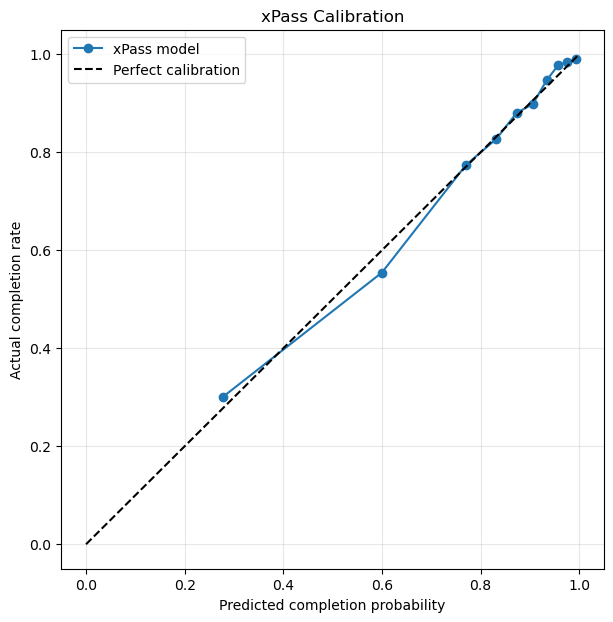

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(0.015099999999999999, 0.454]",0.278378,0.301432,34074,0.023054
"(0.454, 0.72]",0.599887,0.554398,34073,-0.045489
"(0.72, 0.807]",0.770438,0.774073,34073,0.003636
"(0.807, 0.854]",0.831663,0.826930,34073,-0.004733
"(0.854, 0.891]",0.873205,0.880437,34074,0.007232
"(0.891, 0.921]",0.905964,0.898307,34073,-0.007658
"(0.921, 0.946]",0.933957,0.947084,34073,0.013127
"(0.946, 0.967]",0.957224,0.977460,34073,0.020236
"(0.967, 0.985]",0.976063,0.984563,34073,0.008500


In [16]:
# -------------------------------------------
# 6. Check Calibration
# -------------------------------------------

from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    LR_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(prob_pred, prob_true, marker="o", label="xPass model")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", label="Perfect calibration")

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_df = pd.DataFrame({
    "predicted": LR_proba,
    "actual": y_test.values
})

calibration_df["probability_bin"] = pd.qcut(
    calibration_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

### Gradient Booster

In [19]:
# -------------------------------------------
# 7. Train a Gradient Boosting model
# -------------------------------------------
from sklearn.ensemble import HistGradientBoostingClassifier

GB_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=10
)

GB_model.fit(X_train, y_train)

GB_proba = GB_model.predict_proba(X_test)[:, 1]
GB_pred = (GB_proba >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_test, GB_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, GB_proba):.4f}")
print(f"Log Loss:  {log_loss(y_test, GB_proba):.4f}")
print(f"Brier:     {brier_score_loss(y_test, GB_proba):.4f}")

Accuracy:  0.8903
ROC-AUC:   0.9244
Log Loss:  0.2569
Brier:     0.0785


In [33]:
# -------------------------------------------
# 8. Evaluate feature importance
# -------------------------------------------

from sklearn.inspection import permutation_importance

gb_importance = permutation_importance(
    GB_model,
    X_test,
    y_test,
    scoring="neg_log_loss",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": gb_importance.importances_mean,
    "std": gb_importance.importances_std
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

display(importance_df)

,feature,importance,std
4,pass_length,0.107234,0.000264
6,pass_angle_cos,0.092625,0.000435
2,end_x,0.079346,0.000259
3,end_y,0.065879,0.000737
7,is_head_pass,0.022607,0.000130
10,is_chipped,0.011479,0.000115
1,y,0.010200,0.000067
8,is_cross,0.009184,0.000162
5,pass_angle_sin,0.006687,0.000132
9,is_set_piece,0.006258,0.000116


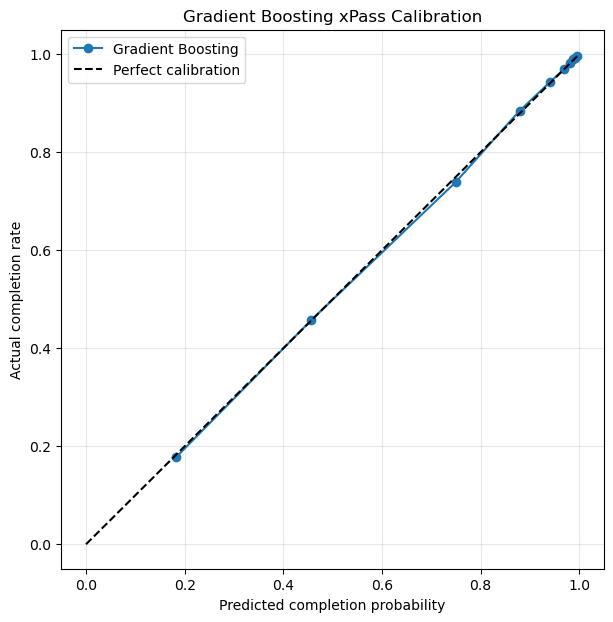

,mean_predicted,actual_completion,pass_count,difference
probability_bin,,,,
"(-0.000552, 0.32]",0.182897,0.177843,34075,-0.005054
"(0.32, 0.619]",0.457011,0.457737,34072,0.000726
"(0.619, 0.834]",0.749401,0.738914,34073,-0.010487
"(0.834, 0.917]",0.879068,0.884601,34073,0.005533
"(0.917, 0.959]",0.940633,0.943124,34074,0.002491
"(0.959, 0.976]",0.968524,0.969243,34073,0.000719
"(0.976, 0.984]",0.980366,0.982420,34073,0.002055
"(0.984, 0.989]",0.986868,0.990814,34074,0.003946
"(0.989, 0.993]",0.990759,0.993279,34072,0.002520


In [23]:
# -------------------------------------------
# 9. Check Calibration
# -------------------------------------------

prob_true, prob_pred = calibration_curve(
    y_test,
    GB_proba,
    n_bins=10,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Gradient Boosting"
)

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

ax.set_xlabel("Predicted completion probability")
ax.set_ylabel("Actual completion rate")
ax.set_title("Gradient Boosting xPass Calibration")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

calibration_gb_df = pd.DataFrame({
    "predicted": GB_proba,
    "actual": y_test.values
})

calibration_gb_df["probability_bin"] = pd.qcut(
    calibration_gb_df["predicted"],
    q=10,
    duplicates="drop"
)

calibration_summary = calibration_gb_df.groupby(
    "probability_bin",
    observed=True
).agg(
    mean_predicted=("predicted", "mean"),
    actual_completion=("actual", "mean"),
    pass_count=("actual", "size")
)

calibration_summary["difference"] = (
    calibration_summary["actual_completion"]
    - calibration_summary["mean_predicted"]
)

display(calibration_summary)

### Evaluation
| Metric | Logistic Regressor 1| Gradient Booster 1| Logistic Regressor 2 | Gradient Booster 2|
|:---|---:|---:|---:|---:|
| Accuracy | 82.90% | 88.48% | 85.58% | **89.03%** |
| ROC-AUC | 0.8054 | 0.9115 | 0.8541 | **0.9244** |
| Log Loss | 0.3846 | 0.2747 | 0.3434 | **0.2569** |
| Brier Score | 0.1215 | 0.0840 | 0.1060 | **0.0785** |

Overall, addding the contextual passing information improves all four metrics for both models. However, the improvement for the Logisitc Regressor is far more considerable. Yet, the second itteration Gradient Booster still remains the better model despite limited improvement, with a ROC-AUC of 0.9244.